## Условие

Решить задачу дискретной оптимизации методом ветвей и границ.

$$\max f = 4x_1 + 6x_2$$

при ограничениях:

$$
\begin{cases}
5x_1 - 2x_2 \ge 10{,}2\\
-2x_1 + x_2 \le 5\\
3x_2 \le 3{,}5\\
x_1 + x_2 \le 3{,}9\\
x_1, x_2 \ge 0 \text{ — целые}
\end{cases}
$$

In [3]:
# Решаем ЛП-релаксации перебором вершин.
# Вершины — пересечения пар граничных прямых.

from itertools import combinations


def solve_lp(extra_constraints):
    """Решает ЛП-релаксацию с учётом дополнительных ограничений
    (для ветвлений). Возвращает (x1, x2, f) или None, если недопустимо."""
    # Базовые ограничения в виде: a1*x1 + a2*x2 <= b
    # Для знака ">=" умножаем на -1.
    base = [
        (-5,  2, -10.2),   # -(5x1 - 2x2) <= -10.2  =>  5x1 - 2x2 >= 10.2
        (-2,  1,   5.0),   # -2x1 + x2 <= 5
        ( 0,  3,   3.5),   # 3x2 <= 3.5
        ( 1,  1,   3.9),   # x1 + x2 <= 3.9
        (-1,  0,   0.0),   # x1 >= 0
        ( 0, -1,   0.0),   # x2 >= 0
    ]
    cons = base + extra_constraints

    verts = []
    # Перебираем все пары ограничений - их пересечения и есть кандидаты в вершины
    for c1, c2 in combinations(cons, 2):
        a1, b1, r1 = c1
        a2, b2, r2 = c2
        D = a1 * b2 - a2 * b1
        if abs(D) < 1e-12:
            continue
        x1 = (r1 * b2 - r2 * b1) / D
        x2 = (a1 * r2 - a2 * r1) / D
        # Проверяем, что точка удовлетворяет всем ограничениям
        ok = all(a * x1 + b * x2 <= r + 1e-9 for (a, b, r) in cons)
        if ok:
            verts.append((x1, x2))

    if not verts:
        return None

    # Ищем максимум f = 4x1 + 6x2
    best = max(verts, key=lambda p: 4 * p[0] + 6 * p[1])
    x1, x2 = best
    f = 4 * x1 + 6 * x2
    return (round(x1, 4), round(x2, 4), round(f, 4))


# Строим дерево ветвлений вручную (по шагам)
print("МЕТОД ВЕТВЕЙ И ГРАНИЦ")
# Узел 0: корень, ЛП-релаксация без дополнительных условий
node0 = solve_lp([])
print(f"\nН0 (корень): {node0}")
print(f"  x1 = {node0[0]}, x2 = {node0[1]} — обе дробные => ветвимся")
print(f"  Верхняя оценка: f = {node0[2]}")

# Ветвимся по x1 (дробное 2.7333): x1 <= 2 или x1 >= 3
print("\nВетвление по x1:")
print("  Ветвь A: x1 <= 2")
print("  Ветвь B: x1 >= 3")

# Ветвь A: x1 <= 2
nodeA = solve_lp([(1, 0, 2.0)])
print(f"\nН1 (x1 <= 2): {nodeA}")
if nodeA is None:
    print("  Недопустимо. Ветвь отсечена.")

# Ветвь B: x1 >= 3  =>  -x1 <= -3
nodeB = solve_lp([(-1, 0, -3.0)])
print(f"\nН2 (x1 >= 3): {nodeB}")
print(f"  x2 = {nodeB[1]} — дробное => ветвимся по x2")

# Ветвимся по x2 (дробное 0.9): x2 <= 0 или x2 >= 1
print("\nВетвление по x2 (при x1 >= 3):")
print("  Ветвь B1: x2 <= 0")
print("  Ветвь B2: x2 >= 1")

# B1: x1 >= 3, x2 <= 0
nodeB1 = solve_lp([(-1, 0, -3.0), (0, 1, 0.0)])
print(f"\nН3 (x1 >= 3, x2 <= 0): {nodeB1}")
print(f"  x1 = {nodeB1[0]} — дробное => ветвимся по x1")

# B2: x1 >= 3, x2 >= 1
nodeB2 = solve_lp([(-1, 0, -3.0), (0, -1, -1.0)])
print(f"\nН4 (x1 >= 3, x2 >= 1): {nodeB2}")
if nodeB2 is None:
    print("  Недопустимо. Ветвь отсечена.")

# Ветвимся по x1 (дробное 3.9): x1 <= 3 или x1 >= 4
print("\nВетвление по x1 (при x1 >= 3, x2 <= 0):")
print("  Ветвь B1a: x1 <= 3")
print("  Ветвь B1b: x1 >= 4")

# B1a: x1 >= 3, x2 <= 0, x1 <= 3  =>  x1 = 3
nodeB1a = solve_lp([(-1, 0, -3.0), (0, 1, 0.0), (1, 0, 3.0)])
print(f"\nН5 (x1 = 3, x2 = 0): {nodeB1a}")
if nodeB1a and abs(nodeB1a[0] - round(nodeB1a[0])) < 1e-6 \
        and abs(nodeB1a[1] - round(nodeB1a[1])) < 1e-6:
    print("  ЦЕЛОЕ решение! f = ", nodeB1a[2])

# B1b: x1 >= 4, x2 <= 0
nodeB1b = solve_lp([(-1, 0, -3.0), (0, 1, 0.0), (-1, 0, -4.0)])
print(f"\nН6 (x1 >= 4, x2 <= 0): {nodeB1b}")
if nodeB1b is None:
    print("  Недопустимо. Ветвь отсечена.")

МЕТОД ВЕТВЕЙ И ГРАНИЦ

Н0 (корень): (2.7333, 1.1667, 17.9333)
  x1 = 2.7333, x2 = 1.1667 — обе дробные => ветвимся
  Верхняя оценка: f = 17.9333

Ветвление по x1:
  Ветвь A: x1 <= 2
  Ветвь B: x1 >= 3

Н1 (x1 <= 2): None
  Недопустимо. Ветвь отсечена.

Н2 (x1 >= 3): (3.0, 0.9, 17.4)
  x2 = 0.9 — дробное => ветвимся по x2

Ветвление по x2 (при x1 >= 3):
  Ветвь B1: x2 <= 0
  Ветвь B2: x2 >= 1

Н3 (x1 >= 3, x2 <= 0): (3.9, -0.0, 15.6)
  x1 = 3.9 — дробное => ветвимся по x1

Н4 (x1 >= 3, x2 >= 1): None
  Недопустимо. Ветвь отсечена.

Ветвление по x1 (при x1 >= 3, x2 <= 0):
  Ветвь B1a: x1 <= 3
  Ветвь B1b: x1 >= 4

Н5 (x1 = 3, x2 = 0): (3.0, -0.0, 12.0)
  ЦЕЛОЕ решение! f =  12.0

Н6 (x1 >= 4, x2 <= 0): None
  Недопустимо. Ветвь отсечена.


/tmp/ipykernel_778/825196774.py:44: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


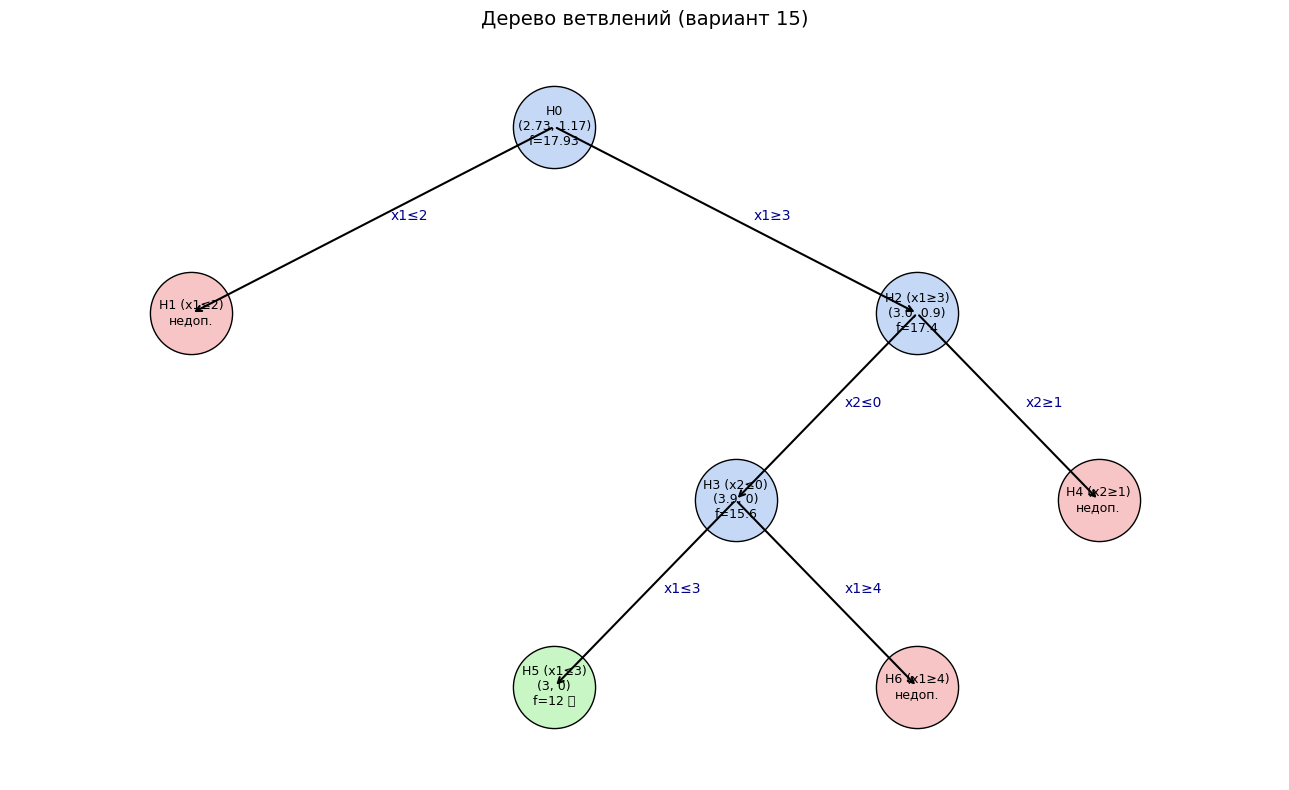

In [4]:
# Граф дерева ветвлений
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 8))

# Координаты узлов
nodes = {
    'Н0': (6, 7, 'Н0\n(2.73, 1.17)\nf=17.93'),
    'Н1': (2, 5, 'Н1 (x1≤2)\nнедоп.'),
    'Н2': (10, 5, 'Н2 (x1≥3)\n(3.0, 0.9)\nf=17.4'),
    'Н3': (8, 3, 'Н3 (x2≤0)\n(3.9, 0)\nf=15.6'),
    'Н4': (12, 3, 'Н4 (x2≥1)\nнедоп.'),
    'Н5': (6, 1, 'Н5 (x1≤3)\n(3, 0)\nf=12 ✅'),
    'Н6': (10, 1, 'Н6 (x1≥4)\nнедоп.'),
}

# Рисуем узлы
for name, (x, y, label) in nodes.items():
    color = '#c8f7c5' if name == 'Н5' else ('#f7c5c5' if 'недоп' in label else '#c5d9f7')
    ax.scatter(x, y, s=3500, c=color, edgecolors='black', zorder=3)
    ax.text(x, y, label, ha='center', va='center', fontsize=9, zorder=4)

# Рисуем рёбра
edges = [
    ('Н0', 'Н1', 'x1≤2'),
    ('Н0', 'Н2', 'x1≥3'),
    ('Н2', 'Н3', 'x2≤0'),
    ('Н2', 'Н4', 'x2≥1'),
    ('Н3', 'Н5', 'x1≤3'),
    ('Н3', 'Н6', 'x1≥4'),
]
for a, b, lab in edges:
    x1, y1, _ = nodes[a]
    x2, y2, _ = nodes[b]
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', lw=1.5))
    ax.text((x1 + x2) / 2 + 0.2, (y1 + y2) / 2,
            lab, fontsize=10, color='darkblue')

ax.set_xlim(0, 14)
ax.set_ylim(0, 8)
ax.axis('off')
ax.set_title('Дерево ветвлений (вариант 15)', fontsize=14)
plt.tight_layout()
plt.show()

## Пояснение

### Шаг 1. ЛП-релаксация (узел Н0)

Решаем задачу **без требования целочисленности**. Оптимум ЛП:

$$x_1 = 2{,}7333,\quad x_2 = 1{,}1667,\quad f = 17{,}9333$$

Обе переменные дробные ⇒ нужно ветвиться.  
Верхняя оценка: $f \le 17{,}93$.

### Шаг 2. Ветвление по x₁

Дробное $x_1 = 2{,}7333 \Rightarrow$ две ветви:

- **A:** $x_1 \le 2$  
- **B:** $x_1 \ge 3$

**Ветвь A.** При $x_1 \le 2$:  
$5x_1 - 2x_2 \ge 10{,}2 \Rightarrow 2x_2 \le 5x_1 - 10{,}2 \le -0{,}2 \Rightarrow x_2 \le -0{,}1$ —  
противоречит $x_2 \ge 0$. **Недопустимо.**

**Ветвь B.** При $x_1 \ge 3$, оптимум ЛП:

$$x_1 = 3{,}0,\quad x_2 = 0{,}9,\quad f = 17{,}4$$

$x_2 = 0{,}9$ — дробное ⇒ ветвимся.

### Шаг 3. Ветвление по x₂

- **B1:** $x_2 \le 0$  
- **B2:** $x_2 \ge 1$

**B2.** При $x_1 \ge 3$ и $x_2 \ge 1$:  
$x_1 + x_2 \ge 4 > 3{,}9$ — противоречит ограничению $x_1 + x_2 \le 3{,}9$.  
**Недопустимо.**

**B1.** При $x_1 \ge 3$, $x_2 \le 0$, оптимум ЛП:

$$x_1 = 3{,}9,\quad x_2 = 0,\quad f = 15{,}6$$

$x_1 = 3{,}9$ — дробное ⇒ ветвимся.

### Шаг 4. Ветвление по x₁

- **B1a:** $x_1 \le 3 \Rightarrow x_1 = 3$ — **ЦЕЛОЕ**, $f = 12$  
- **B1b:** $x_1 \ge 4$ — при $x_1 + x_2 \le 3{,}9$ недопустимо

### Шаг 5. Отсечение и оптимум

Целое решение $x^* = (3,\ 0)$, $f^* = 12$.  
Все остальные ветви либо недопустимы, либо дают оценку меньше $12$.  
**Оптимум найден.**

## Ответ

**Оптимальное целочисленное решение:**

$$x_1^* = 3,\qquad x_2^* = 0$$

**Максимум целевой функции:**

$$f_{\max} = 4 \cdot 3 + 6 \cdot 0 = 12$$

**Проверка ограничений:**

$$
\begin{aligned}
5 \cdot 3 - 2 \cdot 0 &= 15 \ge 10{,}2 \ +\\
-2 \cdot 3 + 0 &= -6 \le 5 \ +\\
3 \cdot 0 &= 0 \le 3{,}5 \ +\\
3 + 0 &= 3 \le 3{,}9 \ +
\end{aligned}
$$

Все ограничения выполнены. Решение целочисленное, значит, оно оптимально по методу ветвей и границ.